# Proyecto Parcial I Aprendizaje Automático
**Universidad de Guayaquil — Carrera de Ciencias de Datos e Inteligencia Artificial**

**Paralelo:** 4-2 **Grupo:** E



**Integrantes:**
- John Jairo Cerezo Ferrín
- Cecilia Lorena Granda Zambrano
- Belén Sarahí Magallón Contreras
- Katherine Nicole Nuñez Sancán


## Parte 1 — Análisis Exploratorio de Datos (EDA)

In [ ]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

In [ ]:

from google.colab import files
uploaded = files.upload()

Saving student-mat.csv to student-mat.csv


In [ ]:
# Cargar dataset
df = pd.read_csv('student-mat.csv')
print(f'Dimensiones del dataset: {df.shape}')
df.head()

Dimensiones del dataset: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
# Información general
print('=== Tipos de datos ===')
print(df.dtypes)
print()
print('=== Valores nulos por columna ===')
print(df.isnull().sum())

=== Tipos de datos ===
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

=== Valores nulos por columna ===
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures   

In [ ]:
# Estadísticas descriptivas de variables numéricas
df.describe().round(2)

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00
mean,16.70,2.75,2.52,1.45,2.04,0.33,3.94,3.24,3.11,1.48,2.29,3.55,5.71,10.91,10.71,10.42
std,1.28,1.09,1.09,0.70,0.84,0.74,0.90,1.00,1.11,0.89,1.29,1.39,8.00,3.32,3.76,4.58
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,3.00,0.00,0.00
25%,16.00,2.00,2.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,3.00,0.00,8.00,9.00,8.00
50%,17.00,3.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,4.00,11.00,11.00,11.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,8.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,75.00,19.00,19.00,20.00


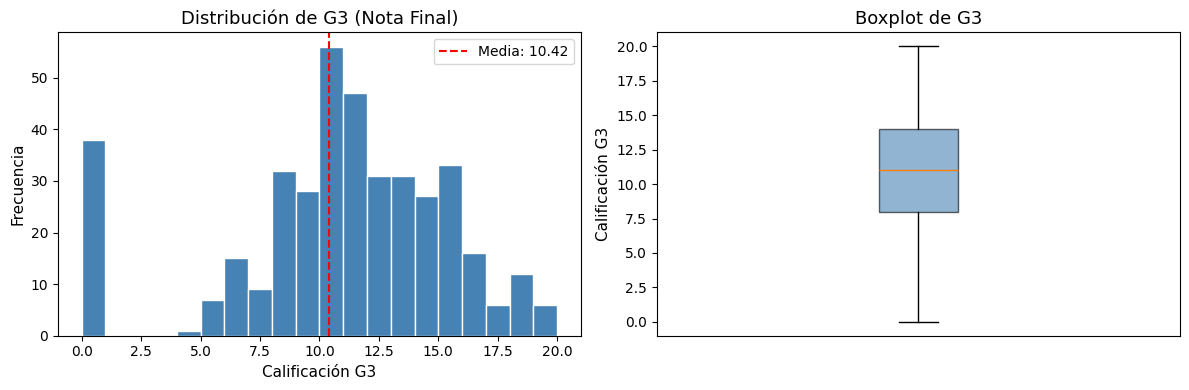

Media G3: 10.42 | Mediana: 11.00 | Desv. Estándar: 4.58


In [ ]:
# Distribución de la variable objetivo G3
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['G3'], bins=20, color='steelblue', edgecolor='white')
axes[0].set_title('Distribución de G3 (Nota Final)')
axes[0].set_xlabel('Calificación G3')
axes[0].set_ylabel('Frecuencia')
axes[0].axvline(df['G3'].mean(), color='red', linestyle='--', label=f'Media: {df["G3"].mean():.2f}')
axes[0].legend()

axes[1].boxplot(df['G3'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[1].set_title('Boxplot de G3')
axes[1].set_ylabel('Calificación G3')
axes[1].set_xticks([])

plt.tight_layout()
plt.show()

print(f'Media G3: {df["G3"].mean():.2f} | Mediana: {df["G3"].median():.2f} | Desv. Estándar: {df["G3"].std():.2f}')

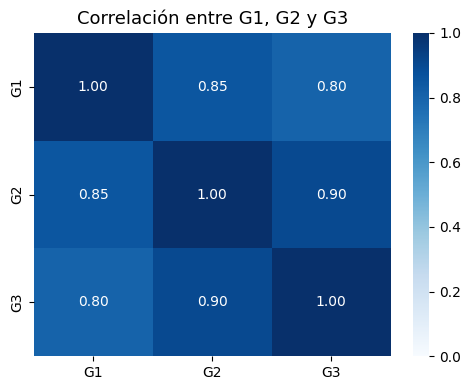

Correlación G1-G3: 0.801
Correlación G2-G3: 0.905


In [ ]:
# Correlación entre G1, G2 y G3
notas = df[['G1', 'G2', 'G3']]
corr = notas.corr()

plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Correlación entre G1, G2 y G3')
plt.tight_layout()
plt.show()

print('Correlación G1-G3:', round(df[['G1','G3']].corr().iloc[0,1], 3))
print('Correlación G2-G3:', round(df[['G2','G3']].corr().iloc[0,1], 3))

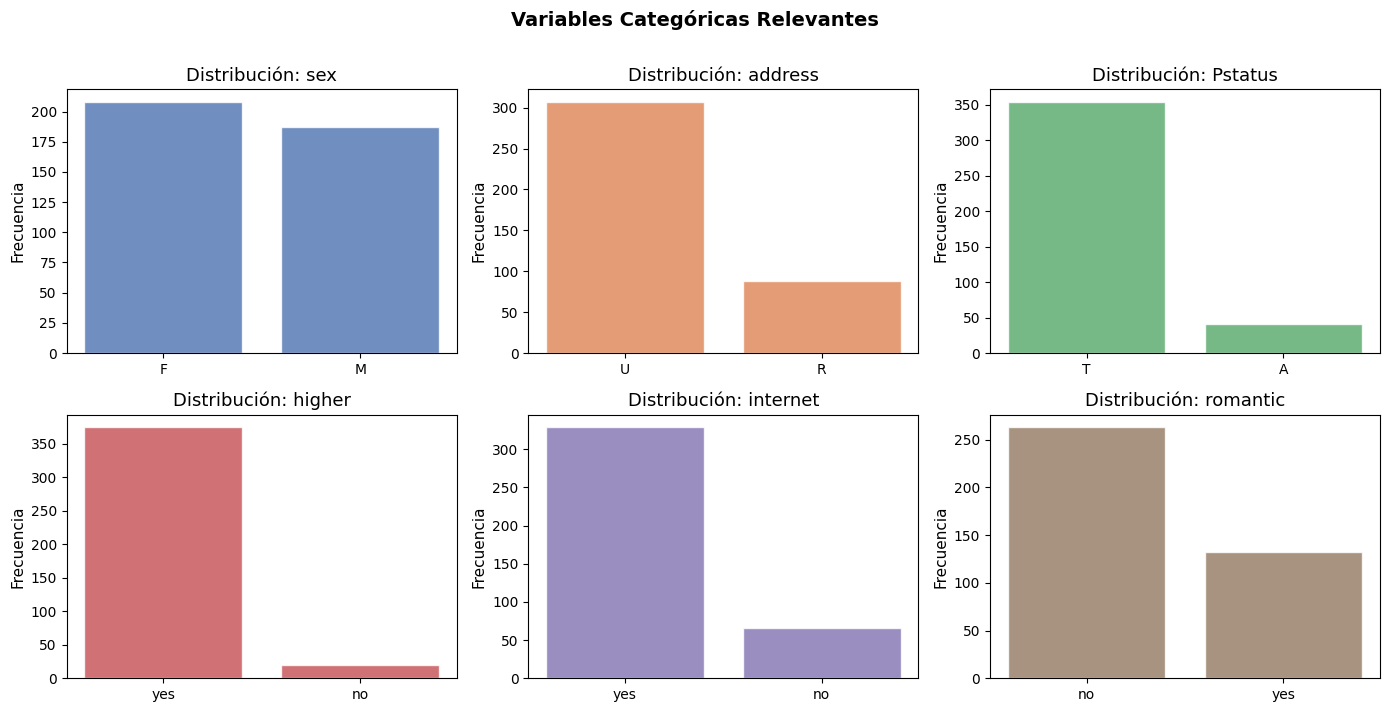

In [ ]:
# Distribución de variables categóricas clave
cat_vars = ['sex', 'address', 'Pstatus', 'higher', 'internet', 'romantic']

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

colores = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2', '#937860']

for i, var in enumerate(cat_vars):
    conteo = df[var].value_counts()
    axes[i].bar(conteo.index, conteo.values, color=colores[i], alpha=0.8, edgecolor='white')
    axes[i].set_title(f'Distribución: {var}')
    axes[i].set_ylabel('Frecuencia')

plt.suptitle('Variables Categóricas Relevantes', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

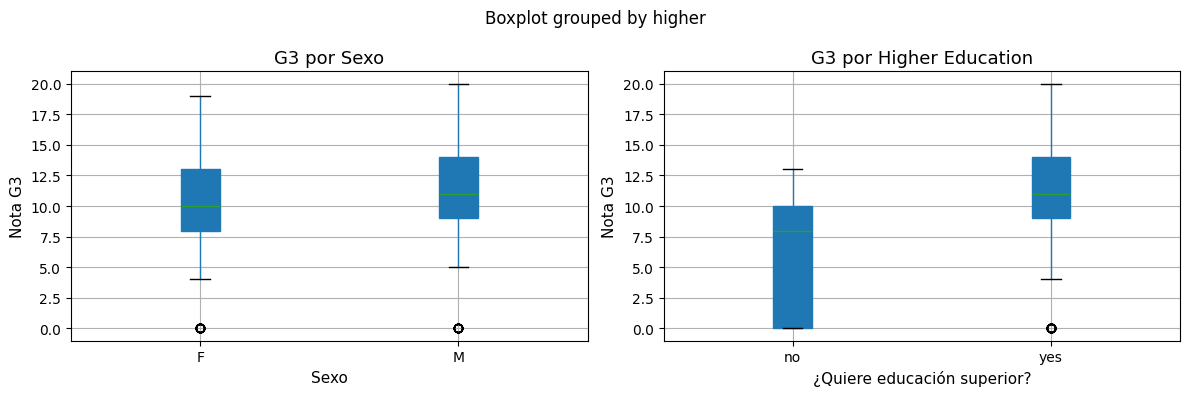

In [ ]:
# G3 según variables categóricas
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.boxplot(column='G3', by='sex', ax=axes[0], patch_artist=True)
axes[0].set_title('G3 por Sexo')
axes[0].set_xlabel('Sexo')
axes[0].set_ylabel('Nota G3')
plt.sca(axes[0])
plt.title('G3 por Sexo')

df.boxplot(column='G3', by='higher', ax=axes[1], patch_artist=True)
axes[1].set_title('G3 según deseo de educación superior')
axes[1].set_xlabel('¿Quiere educación superior?')
axes[1].set_ylabel('Nota G3')
plt.sca(axes[1])
plt.title('G3 por Higher Education')

plt.tight_layout()
plt.show()

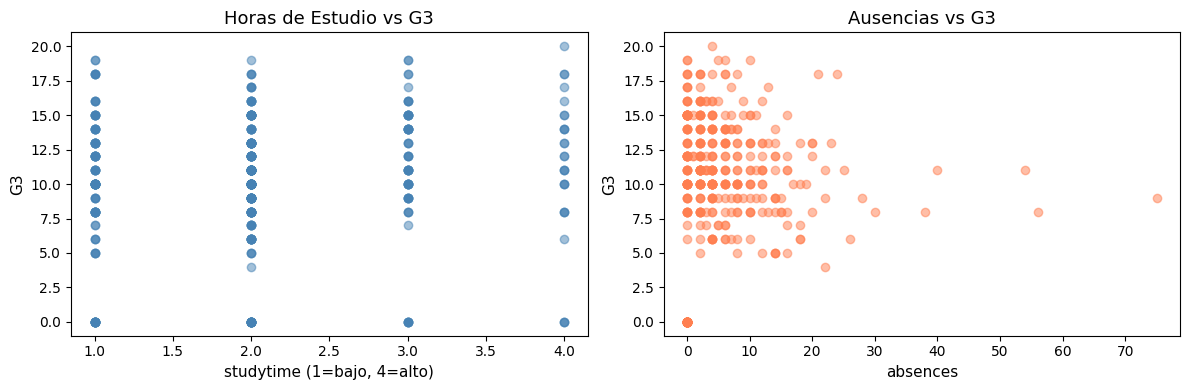

In [ ]:
# Relación entre studytime, absences y G3
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df['studytime'], df['G3'], alpha=0.5, color='steelblue')
axes[0].set_title('Horas de Estudio vs G3')
axes[0].set_xlabel('studytime (1=bajo, 4=alto)')
axes[0].set_ylabel('G3')

axes[1].scatter(df['absences'], df['G3'], alpha=0.5, color='coral')
axes[1].set_title('Ausencias vs G3')
axes[1].set_xlabel('absences')
axes[1].set_ylabel('G3')

plt.tight_layout()
plt.show()

Q1=0.0, Q3=8.0, IQR=8.0, Límite superior=20.0
Outliers detectados en absences: 15


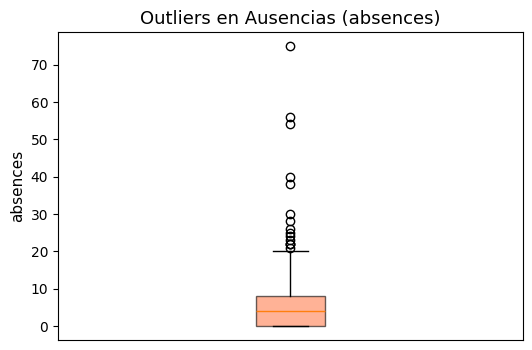

In [ ]:
# Detección visual de outliers en absences
plt.figure(figsize=(6, 4))
plt.boxplot(df['absences'], vert=True, patch_artist=True,
            boxprops=dict(facecolor='coral', alpha=0.6))
plt.title('Outliers en Ausencias (absences)')
plt.ylabel('absences')
plt.xticks([])

Q1 = df['absences'].quantile(0.25)
Q3 = df['absences'].quantile(0.75)
IQR = Q3 - Q1
limite = Q3 + 1.5 * IQR
n_outliers = (df['absences'] > limite).sum()
print(f'Q1={Q1}, Q3={Q3}, IQR={IQR}, Límite superior={limite}')
print(f'Outliers detectados en absences: {n_outliers}')
plt.show()